# Monte Carlo price paths

This notebook documents CryptoQuantLab's Monte Carlo engine: three models of daily returns, how paths are drawn and checked, how much a given number of paths can be trusted, what the models say about Bitcoin's next 30 days, and whether their 10-day VaR held up out of sample. The engine will drive a Scenario tab with fan charts and loss distributions; it is not on the site yet.

The engine is [`backend/src/models/monteCarlo.ts`](../../backend/src/models/monteCarlo.ts), with its random numbers in [`random.ts`](../../backend/src/models/random.ts). The reference here, [`cql_validation/monte_carlo.py`](../cql_validation/monte_carlo.py), draws the same numbers in the same order, so the tests compare whole paths: they match to 1e-12, and the generator matches numpy bit for bit.

**The main result is that all three models overstated 10-day risk over the test period, the GARCH bootstrap least.** It broke its 95% VaR about three quarters as often as it should have, the normal model about half as often and the Student-t less still. About half of all exceptions came in two market-wide falls, so the test has far fewer independent observations than its forecast count suggests.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent))
from cql_validation import garch, monte_carlo as mc, returns, var

plt.rcParams.update({"figure.figsize": (9, 3.4), "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

btc = pd.read_csv("../data/bitcoin_usd_daily.csv", parse_dates=["date"])
r = returns.log_returns(btc["price_usd"].to_numpy())
print(f"{len(r)} daily log returns, {btc.date.iloc[1]:%Y-%m-%d} to {btc.date.iloc[-1]:%Y-%m-%d}")

363 daily log returns, 2025-10-24 to 2026-10-21


\
## 1. Three models of daily returns

Each model gives daily log returns $r_t$, and a path's price relative after $d$ days is $\exp(\sum_{t \le d} r_t)$.

- **Normal** (geometric Brownian motion): $r_t = \mu + \sigma z_t$ with $z_t \sim N(0, 1)$, the sample mean and \
standard deviation.
- **Student-t:** $r_t = m + s\, t_\nu$, with location, scale and degrees of freedom fitted by maximum likelihood. \
Fat tails, but no volatility clustering.
- **GARCH bootstrap** (filtered historical simulation): the GARCH(1,1) fit of the GARCH notebook, with shocks \
resampled from its standardized residuals rather than assumed normal:

$$r_t = \mu + \sqrt{h_t}\, z_t, \qquad h_{t+1} = \omega + \alpha (r_t - \mu)^2 + \beta h_t, \qquad z_t \in \{\hat z_1, \dots, \hat z_n\}.$$

$h_1$ is the one-step-ahead variance, so paths start at today's volatility and drift towards the long-run level. This \
keeps both the clustering and the empirical tail shape.

In [2]:
models = {"normal": mc.gbm(r), "Student-t": mc.student_t(r), "GARCH bootstrap": mc.garch_bootstrap(r)}
g = models["GARCH bootstrap"]
t_model = models["Student-t"]
pd.DataFrame({
    "parameters": [
        f"mu {models['normal'].mu:.5f}, sigma {models['normal'].sigma:.5f}",
        f"location {t_model.location:.5f}, scale {t_model.scale:.5f}, dof {t_model.dof:.3f}",
        f"omega {g.omega:.3g}, alpha {g.alpha:.3f}, beta {g.beta:.3f}",
    ],
    "daily volatility now": [models["normal"].sigma, t_model.scale * np.sqrt(t_model.dof / (t_model.dof - 2)), np.sqrt(g.next_variance)],
    "long-run daily volatility": [models["normal"].sigma, t_model.scale * np.sqrt(t_model.dof / (t_model.dof - 2)), np.sqrt(g.omega / (1 - g.alpha - g.beta))],
}, index=pd.Index(models, name="model"))

,parameters,daily volatility now,long-run daily volatility
model,,,
normal,"mu -0.00072, sigma 0.02300",0.0229995,0.0229995
Student-t,"location -0.00089, scale 0.01532, dof 3.425",0.0237549,0.0237549
GARCH bootstrap,"omega 9.43e-05, alpha 0.191, beta 0.635",0.0176706,0.0233021


The Student-t fit has about 3.4 degrees of freedom: its variance is finite but its fourth moment is not, so very large days are far more likely than under the normal. GARCH puts current volatility below its long-run level, so its paths start calm and widen.

## 2. Random numbers

The generator is numpy's SFC64, seeded as its author specifies. A uniform is the top 53 bits of an output, as in numpy's `Generator.random()`. Normals come from Box-Muller, gamma variables from Marsaglia and Tsang's method, and a Student-t from a normal divided by the square root of a scaled chi-square:

$$z = \sqrt{-2 \log u_1} \cos(2 \pi u_2), \qquad t_\nu = z \Big/ \sqrt{\chi^2_\nu / \nu}, \qquad \chi^2_\nu = 2\, \Gamma(\nu / 2, 1).$$

The backend's tests check the raw outputs against numpy for three seeds, bit for bit. The cell below checks the distributions against scipy with Kolmogorov-Smirnov tests on 50,000 draws each.

In [3]:
stream = mc.Stream(2026)
n = 50_000
draws = {
    "uniform": ([stream.uniform() for _ in range(n)], stats.uniform.cdf),
    "normal": ([stream.normal() for _ in range(n)], stats.norm.cdf),
    "gamma, shape 1.7": ([stream.gamma(1.7) for _ in range(n)], lambda x: stats.gamma.cdf(x, 1.7)),
    "gamma, shape 10": ([stream.gamma(10.0) for _ in range(n)], lambda x: stats.gamma.cdf(x, 10.0)),
    f"Student-t, {t_model.dof:.2f} dof": (
        [stream.normal() * np.sqrt(t_model.dof / (2 * stream.gamma(t_model.dof / 2))) for _ in range(n)],
        lambda x: stats.t.cdf(x, t_model.dof),
    ),
}
pd.DataFrame(
    {name: dict(zip(["KS statistic", "p-value"], stats.kstest(x, cdf))) for name, (x, cdf) in draws.items()}
).T

,KS statistic,p-value
uniform,0.00483834,0.191682
normal,0.00576711,0.0715968
"gamma, shape 1.7",0.00526425,0.1247
"gamma, shape 10",0.00443023,0.279361
"Student-t, 3.43 dof",0.00346202,0.585507


None of the tests rejects at the 5% level. The backend runs the same kind of test against its own validated CDFs, and its tests also confirm that at that sample size the test rejects a normal with 5% too much spread and a gamma with shape 4.1 instead of 4.

## 3. Checks against closed forms

The normal model's 30-day log return is exactly $N(30\mu, 30\sigma^2)$, so its fan has known quantiles. For the GARCH bootstrap, the shock is independent of the variance, so $E[e_d^2] = m_2 E[h_d]$ with $m_2$ the residuals' mean square, and

$$E[h_{d+1}] = \omega + (\alpha m_2 + \beta)\, E[h_d].$$

With $m_2 = 1$ this is the usual GARCH variance forecast.

In [4]:
days, paths = 30, 20_000
normal_paths = mc.simulate(models["normal"], paths, days, seed=3)
quantiles = [0.05, 0.25, 0.5, 0.75, 0.95]
simulated = np.quantile(np.exp(normal_paths), quantiles, axis=0)
exact = np.exp(np.arange(1, days + 1) * models["normal"].mu + np.sqrt(np.arange(1, days + 1)) * models["normal"].sigma * stats.norm.ppf(quantiles)[:, None])
print(f"normal fan, largest gap to the lognormal quantiles over 30 days: {np.abs(simulated / exact - 1).max():.2%}")

garch_paths = mc.simulate(g, paths, days, seed=5)
shocks = np.diff(np.c_[np.zeros(paths), garch_paths], axis=1) - g.mu
m2 = (g.residuals**2).mean()
expected = [g.next_variance]
for _ in range(days - 1):
    expected.append(g.omega + (g.alpha * m2 + g.beta) * expected[-1])
standard_error = (shocks**2).std(axis=0, ddof=1) / np.sqrt(paths)
fit = garch.fit_log_returns(r)
pd.DataFrame({
    "simulated E[e^2]": (shocks**2).mean(axis=0),
    "m2 E[h]": m2 * np.array(expected),
    "gap in standard errors": ((shocks**2).mean(axis=0) - m2 * np.array(expected)) / standard_error,
    "GARCH forecast (m2 = 1)": [garch.forecast_variance(fit, d) for d in range(1, days + 1)],
}, index=pd.Index(range(1, days + 1), name="day")).iloc[[0, 1, 4, 9, 19, 29]]

normal fan, largest gap to the lognormal quantiles over 30 days: 0.23%


,simulated E[e^2],m2 E[h],gap in standard errors,GARCH forecast (m2 = 1)
day,,,,
1,0.000308303,0.000311397,-0.66335,0.00031225
2,0.000352612,0.000351184,0.240673,0.00035231
5,0.000433681,0.000433592,0.0118577,0.000435379
10,0.000496551,0.000499046,-0.208371,0.000501516
20,0.000522288,0.000533854,-1.18451,0.000536829
30,0.000555773,0.000538992,1.31581,0.000542074


The simulated lognormal fan is within sampling error of the exact quantiles, and the simulated GARCH variances follow the recursion within a few standard errors on every day. The residuals' mean square is slightly below 1, so the bootstrap's variance sits slightly below the textbook forecast.

## 4. How many paths, and do antithetic pairs help?

Each antithetic pair shares its draws, mirrored, so a pair's errors offset. The cell repeats each simulation 100 times with 1,000 paths and measures how much the estimates vary between runs.

In [5]:
def spread(model, antithetic, runs=100, paths=1000, days=30):
    rows = []
    for seed in range(runs):
        s = mc.summarize(mc.simulate(model, paths, days, 1000 + seed, antithetic), antithetic, [0.5], 0.05, [])
        rows.append([s["mean"], s["valueAtRisk"], s["expectedShortfall"]])
    return np.std(rows, axis=0, ddof=1)

variance_ratio = {}
for name, model in models.items():
    variance_ratio[name] = (spread(model, False) / spread(model, True)) ** 2
pd.DataFrame(variance_ratio, index=["mean return", "95% VaR", "95% ES"]).rename_axis("variance without pairs / with pairs")

,normal,Student-t,GARCH bootstrap
variance without pairs / with pairs,,,
mean return,60.203,26.7839,29.8567
95% VaR,1.01342,1.35455,0.962177
95% ES,0.975237,0.977509,0.942098


**Antithetic pairs make the mean far more precise but don't help the tail.** The mean is a linear average, so a path and its mirror cancel each other's noise. VaR and ES depend only on the worst paths, and a bad path's mirror is a good one, which tells the estimate nothing about the tail. So the Scenario tab's tail figures need more paths, not pairs. Their error falls as $1/\sqrt{N}$:

In [6]:
rng = np.random.default_rng(1)
precision = {}
for paths in (1000, 4000, 16000):
    estimates = [var.historical(np.exp(mc.simulate_horizon(g, paths, 30, rng)) - 1, 0.05)[0] for _ in range(100)]
    precision[paths] = {"95% VaR, mean": np.mean(estimates), "standard deviation between runs": np.std(estimates, ddof=1)}
pd.DataFrame(precision).T.rename_axis("paths")

,"95% VaR, mean",standard deviation between runs
paths,,
1000,0.197803,0.00727015
4000,0.197796,0.00405799
16000,0.198321,0.00197518


Quadrupling the paths roughly halves the error, as expected. With 10,000 paths, a 30-day 95% VaR is known to within about a quarter of a percentage point.

## 5. Bitcoin over the next 30 days

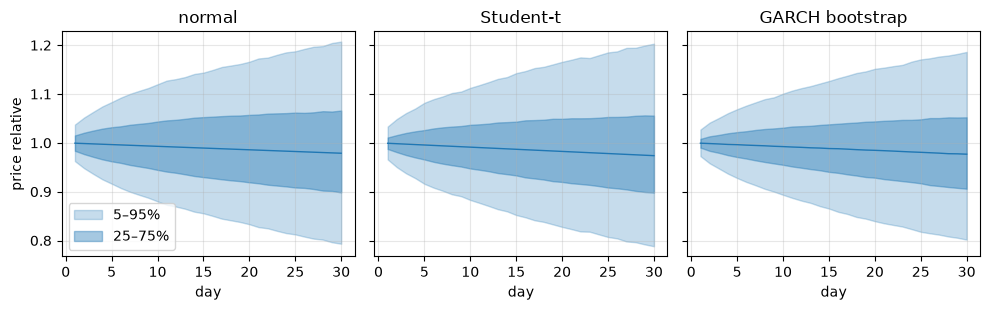

,95% VaR,95% ES,99% VaR,99% ES,P(drawdown >= 20%),P(drawdown >= 30%)
normal,20.7%,24.2%,26.8%,29.3%,13.1%,0.8%
Student-t,21.2%,26.1%,28.7%,33.6%,12.5%,1.5%
GARCH bootstrap,19.8%,25.2%,27.9%,33.9%,11.0%,1.5%


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
rows = {}
for ax, (name, model) in zip(axes, models.items()):
    x = mc.simulate(model, 10_000, 30, seed=1, antithetic=True)
    s95 = mc.summarize(x, True, [0.05, 0.25, 0.5, 0.75, 0.95], 0.05, [0.2, 0.3])
    s99 = mc.summarize(x, True, [0.5], 0.01, [])
    fan = np.array(s95["fan"])
    day = np.arange(1, 31)
    ax.fill_between(day, fan[:, 0], fan[:, 4], alpha=0.25, color="tab:blue", label="5–95%")
    ax.fill_between(day, fan[:, 1], fan[:, 3], alpha=0.4, color="tab:blue", label="25–75%")
    ax.plot(day, fan[:, 2], color="tab:blue", lw=1)
    ax.set_title(name)
    ax.set_xlabel("day")
    rows[name] = {
        "95% VaR": s95["valueAtRisk"], "95% ES": s95["expectedShortfall"],
        "99% VaR": s99["valueAtRisk"], "99% ES": s99["expectedShortfall"],
        "P(drawdown >= 20%)": s95["drawdownProbabilities"][0], "P(drawdown >= 30%)": s95["drawdownProbabilities"][1],
    }
axes[0].set_ylabel("price relative")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()
pd.DataFrame(rows).T.map(lambda v: f"{v:.1%}")

The models nearly agree at 95% and part in the far tail. At 99% the two fat-tailed models put expected shortfall around 34%, against about 29% for the normal, and they make a 30% drawdown within the month about twice as likely. GARCH's fan starts narrower than the others, because current volatility is below its long-run level.

## 6. Did 10-day VaR hold out of sample?

[`scripts/monte_carlo_cross_section.py`](../scripts/monte_carlo_cross_section.py) refits each model on every stored coin's previous 180 returns, simulates 10 days ahead with 5,000 paths, and counts how often the realized loss beat VaR. Periods don't overlap. Each model also runs with zero drift, a common choice for risk because a window's mean return is mostly noise. Only coins with daily volatility of at least 0.5% are counted, which removes stablecoins and tokenized funds.

In [8]:
cross_section = pd.read_csv("../data/monte_carlo_cross_section.csv")
coins = cross_section[cross_section.daily_volatility >= 0.005]
forecasts = coins.forecasts.sum()
names = {"gbm": "normal", "student_t": "Student-t", "garch_bootstrap": "GARCH bootstrap"}

rows = {}
for stem, name in names.items():
    for drift, label in (("", "window mean"), ("_zero_drift", "zero")):
        row = {}
        for level, alpha in (("95", 0.05), ("99", 0.01)):
            exceptions = coins[f"{stem}{drift}_exceptions_{level}"]
            count = int(exceptions.sum())
            hits = [True] * count + [False] * (forecasts - count)
            row[f"{level}% exceptions"] = count / forecasts
            row[f"{level}% Kupiec p"] = var.kupiec(hits, alpha)[1]
            row[f"{level}% loss / ES"] = (coins[f"{stem}{drift}_es_ratio_{level}"].fillna(0) * exceptions).sum() / count
        rows[(name, label)] = row
print(f"{len(coins)} coins, {forecasts} forecasts per model; nominal rates 5% and 1%")
pd.DataFrame(rows).T.rename_axis(["model", "drift"])

83 coins, 1467 forecasts per model; nominal rates 5% and 1%


95% exceptions  95% Kupiec p  95% loss / ES  \
model           drift                                                      
normal          window mean       0.0293115   8.56839e-05       0.987749   
                zero              0.0259032   3.34578e-06         1.0096   
Student-t       window mean       0.0197682   1.71286e-09       0.913761   
                zero              0.0259032   3.34578e-06       0.920218   
GARCH bootstrap window mean       0.0374915     0.0216894         1.0186   
                zero              0.0381731     0.0303858        1.04546   

                             99% exceptions  99% Kupiec p  99% loss / ES  
model           drift                                                     
normal          window mean      0.00408998    0.00984288        1.11877  
                zero             0.00408998    0.00984288        1.15314  
Student-t       window mean      0.00136333    2.9041e-05        1.19686  
                zero             0.00272665   0.000900312        1.05268  
GARCH bootstrap window mean      0.00613497      0.109068        1.14516  
                zero             0.00886162      0.654976        1.13551

Read with section 7's caveat, three things stand out:

- **Every model was conservative, and the GARCH bootstrap least.** It broke 95% VaR on about 3.8% of forecasts and 99% VaR on 0.6–0.9%. The normal model broke 95% VaR about half as often as it should, and the Student-t less still: over this period its heavy tails cost more than they gave.
- **Expected shortfall was about right.** When VaR was broken, the average loss was roughly the ES the model predicted, the "loss / ES" columns.
- **Drift changes little.** Setting it to zero moves the rates by under a percentage point, and not in the same direction for every model.

The Kupiec p-values assume independent exceptions, which these are not, as the next cell shows.

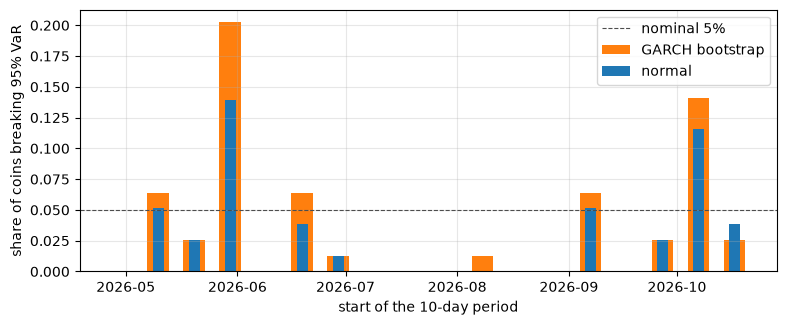

18 common periods; the two worst hold 27 of 50 GARCH bootstrap exceptions


In [9]:
periods = pd.read_csv("../data/monte_carlo_periods.csv", parse_dates=["date"])
periods = periods[periods.coins >= 10]
fig, ax = plt.subplots()
ax.bar(periods.date, periods.garch_bootstrap_exceptions_95 / periods.coins, width=6, color="tab:orange", label="GARCH bootstrap")
ax.bar(periods.date, periods.gbm_exceptions_95 / periods.coins, width=3, color="tab:blue", label="normal")
ax.axhline(0.05, color="0.3", lw=0.8, ls="--", label="nominal 5%")
ax.set_ylabel("share of coins breaking 95% VaR")
ax.set_xlabel("start of the 10-day period")
ax.legend()
plt.show()

top_two = periods.garch_bootstrap_exceptions_95.nlargest(2).sum()
print(f"{len(periods)} common periods; the two worst hold {top_two} of {periods.garch_bootstrap_exceptions_95.sum()} GARCH bootstrap exceptions")

Exceptions come in waves. Crypto coins fall together, so in most 10-day periods almost no coin broke its VaR, and in the two market-wide falls 14–20% of coins did. The test therefore has about 18 independent periods rather than 1,467 forecasts, and the pooled p-values overstate how sure we can be. A longer history, or a joint model of coins, is needed to separate the models properly.

## 7. Limitations

- **One path at a time.** Each coin is simulated alone. A portfolio needs joint paths with correlated shocks, which the Scenario tab will need for more than one holding.
- **Parameters are fixed.** Each simulation uses one fitted model and ignores the uncertainty in its parameters, which makes the fan too narrow, more so for long horizons.
- **A year of residuals.** The bootstrap can only replay shocks from the past year; a crash larger than any in the window can't appear, except through a high variance.
- **A short test.** Six months, with two market-wide falls, so the out-of-sample counts are descriptive rather than a formal comparison of the models.
- **Monte Carlo noise in the test.** With 5,000 paths a VaR estimate moves by a few tenths of a percentage point between runs, enough to flip borderline exceptions.

## References

- Barone-Adesi, G., Giannopoulos, K. and Vosper, L. (1999). VaR without correlations for portfolios of derivative securities. *Journal of Futures Markets*, 19(5), 583–602.
- Box, G. E. P. and Muller, M. E. (1958). A note on the generation of random normal deviates. *Annals of Mathematical Statistics*, 29(2), 610–611.
- Glasserman, P. (2004). *Monte Carlo Methods in Financial Engineering*. Springer.
- Hammersley, J. M. and Morton, K. W. (1956). A new Monte Carlo technique: antithetic variates. *Mathematical Proceedings of the Cambridge Philosophical Society*, 52(3), 449–475.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- Marsaglia, G. and Tsang, W. W. (2000). A simple method for generating gamma variables. *ACM Transactions on Mathematical Software*, 26(3), 363–372.
- NumPy. SFC64 bit generator. https://numpy.org/doc/stable/reference/random/bit_generators/sfc64.html